<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import random

In [3]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [4]:
len(l)

10000

In [5]:
l[:5]

[6, 8, 7, 7, 5]

In [6]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0270
3     0.0590
4     0.0803
5     0.1144
6     0.1384
7     0.1645
8     0.1393
9     0.1157
10    0.0816
11    0.0529
12    0.0269
Name: count, dtype: float64


<Axes: >

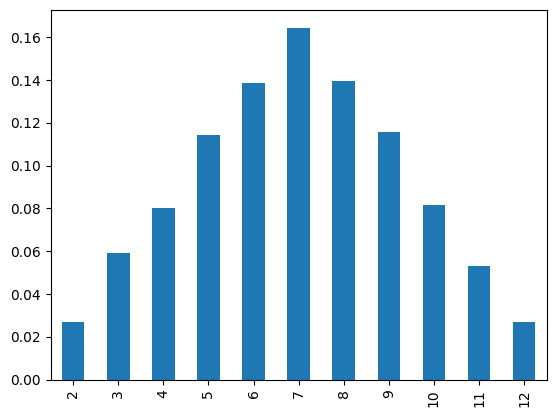

In [7]:
s.plot(kind='bar')

<Axes: >

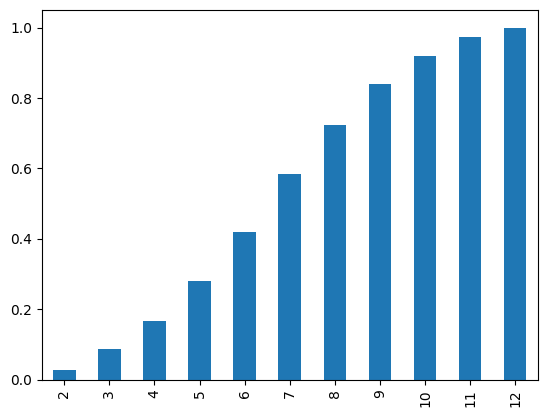

In [8]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [9]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[49.1987005  55.61837314 34.29102918 50.14970564 54.36295174 51.31265114
 55.67717006 44.61535435 47.20264539 56.10534447 53.84388062 49.80194391
 43.69887413 49.97594412 41.14369291 48.98223888 45.03935222 44.18581442
 47.15749868 54.12889635 50.61148497 46.59273487 49.71589013 51.16096408
 52.23963488 45.9376847  45.61050123 59.82368603 48.9835139  45.29978823
 56.65407662 52.67191375 53.26130299 61.61725781 52.18474818 46.63285448
 52.76385477 58.27230418 48.00215196 46.45418391 45.24042008 46.84033727
 60.64534352 49.95049484 41.40967406 47.07871547 50.51157424 44.67381526
 50.13382089 46.0141675  58.33587517 54.7144555  49.12936256 51.62680821
 42.67968944 45.40527284 54.24787166 50.96769573 51.39260504 56.60167489
 48.76444258 53.67571024 54.0902482  47.9385939  48.81482711 48.28333721
 50.90865393 58.92488205 57.08436695 51.75535322 50.05078642 51.24184506
 41.68778449 45.99698469 49.24069754 48.73985607 44.18376382 44.61921685
 50.91934474 45.63150485 47.31966956 38.81286995 46

In [10]:
sample.mean()

np.float64(50.0644478267316)

(array([  3.,  13.,  53., 146., 270., 281., 160.,  65.,   8.,   1.]),
 array([31.78468732, 35.41866403, 39.05264075, 42.68661747, 46.32059418,
        49.9545709 , 53.58854762, 57.22252434, 60.85650105, 64.49047777,
        68.12445449]),
 <BarContainer object of 10 artists>)

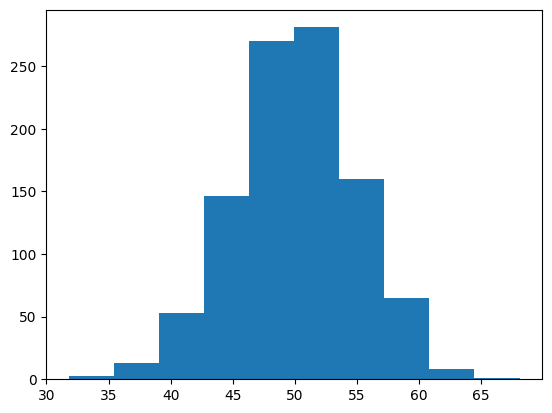

In [11]:
plt.hist(sample,bins=10)

In [12]:
sample_mean=sample.mean()
sample_std=sample.std()

In [13]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [14]:
sample.min()

np.float64(31.78468731604999)

In [15]:
sample.max()

np.float64(68.12445448841156)

In [16]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [17]:
probabilities=[dist.pdf(value) for value in values]

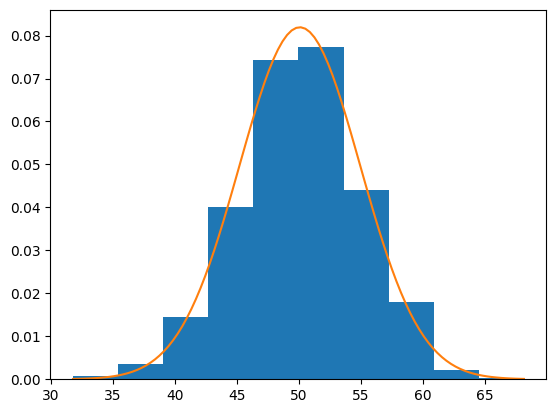

In [18]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_1722/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

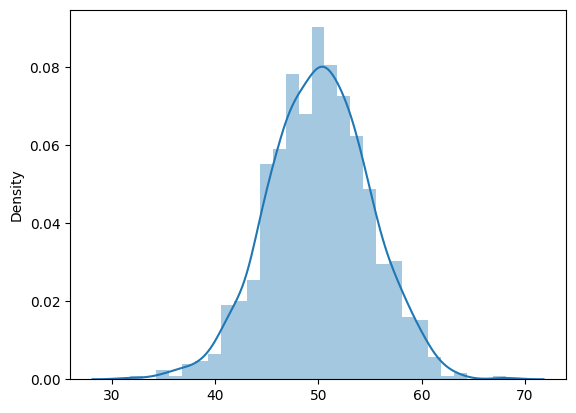

In [19]:
import seaborn as sns
sns.distplot(sample)

KDE

In [20]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [21]:
sample

array([20.33304274, 16.9675284 , 17.75951626, 22.71728906, 17.07904145,
       18.60235889, 24.44773634, 13.98881564, 23.48288396, 24.54130591,
       24.00357402, 19.82967439, 18.40867018, 18.04078588, 30.88888462,
       19.35116495, 22.45119579, 14.55703617, 18.9550259 , 33.45272111,
       19.93298745, 23.0070094 , 20.07859601, 20.42143273, 20.52504719,
       16.29289165, 18.59566099, 15.24615395, 20.16367357, 22.54649935,
       21.23329819, 15.11226334, 11.52163708, 17.10684796, 13.79130891,
       25.82767798, 22.7861063 , 24.38830491, 28.36165364, 18.50015729,
       17.05524811, 18.30715225, 21.57260182, 20.69147619, 16.61615438,
       23.00261475, 19.17359901, 18.72554144, 12.99983184, 18.80598083,
       19.04206244, 20.82387181, 22.70578294,  8.51970315, 20.04218206,
       11.65516246, 23.62044496, 21.60730123, 17.24586543, 17.64690803,
       13.70641811, 17.48032687, 26.19173912, 12.9159042 , 18.58808786,
       21.95234499, 19.53979776, 23.4822351 , 11.22359454, 21.76

(array([ 1.,  1.,  0.,  2.,  3.,  3., 10.,  7., 13., 10., 17., 15., 24.,
        27., 22., 27., 17., 22., 21., 11., 10., 14.,  7.,  9.,  7., 13.,
        14., 21., 29., 32., 32., 38., 45., 50., 52., 41., 58., 52., 43.,
        31., 35., 38., 27., 17., 18.,  7.,  2.,  3.,  1.,  1.]),
 array([ 4.86652717,  5.85966103,  6.85279488,  7.84592874,  8.8390626 ,
         9.83219646, 10.82533031, 11.81846417, 12.81159803, 13.80473188,
        14.79786574, 15.7909996 , 16.78413346, 17.77726731, 18.77040117,
        19.76353503, 20.75666888, 21.74980274, 22.7429366 , 23.73607045,
        24.72920431, 25.72233817, 26.71547203, 27.70860588, 28.70173974,
        29.6948736 , 30.68800745, 31.68114131, 32.67427517, 33.66740902,
        34.66054288, 35.65367674, 36.6468106 , 37.63994445, 38.63307831,
        39.62621217, 40.61934602, 41.61247988, 42.60561374, 43.5987476 ,
        44.59188145, 45.58501531, 46.57814917, 47.57128302, 48.56441688,
        49.55755074, 50.55068459, 51.54381845, 52.53695231,

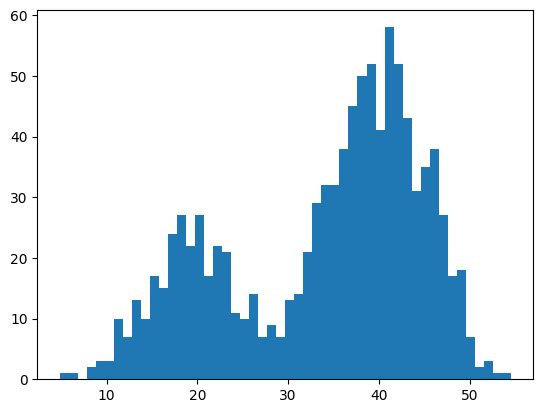

In [22]:
plt.hist(sample,bins=50)

In [23]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [24]:
dataset=sns.load_dataset("iris")

In [25]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

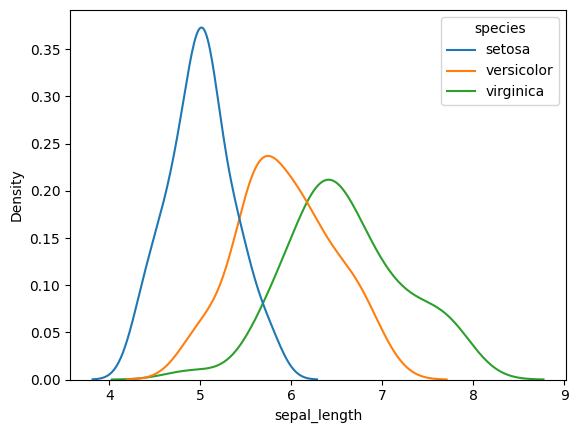

In [26]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

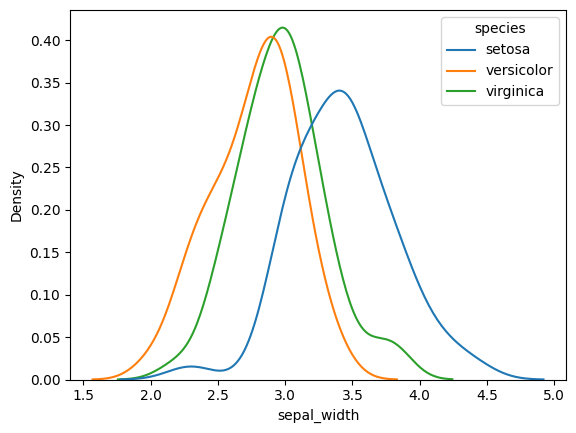

In [27]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

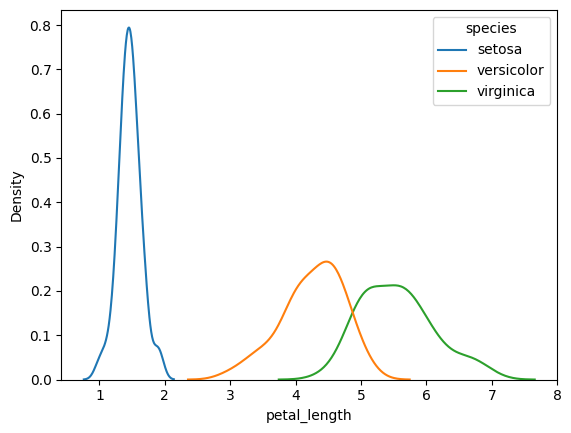

In [28]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

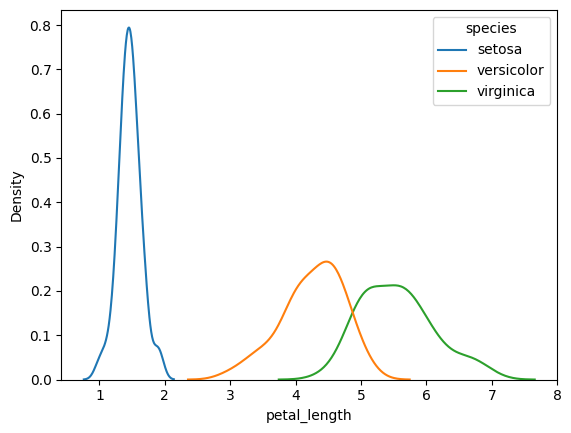

In [29]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [30]:
tips=sns.load_dataset("tips")

In [31]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

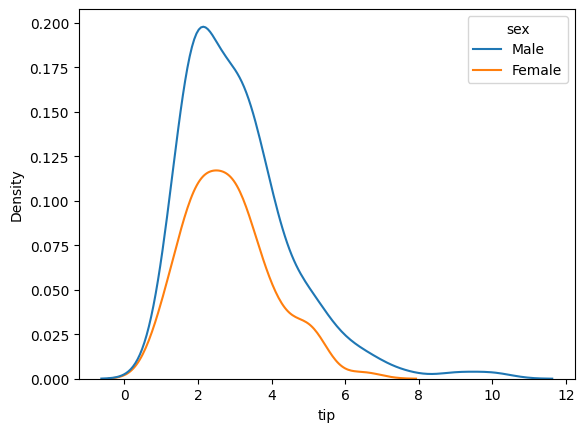

In [32]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

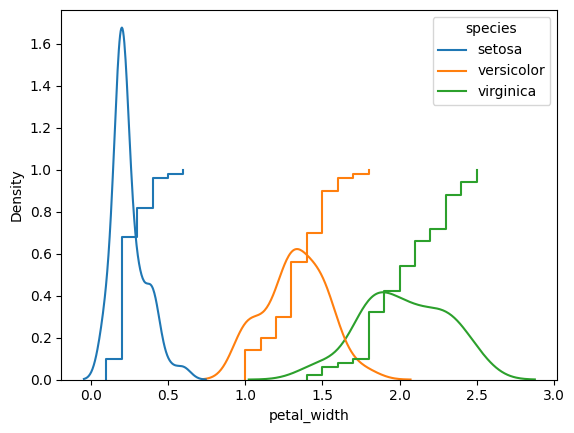

In [33]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [34]:
#contour plots

How to find distribution is normal or not?

In [35]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

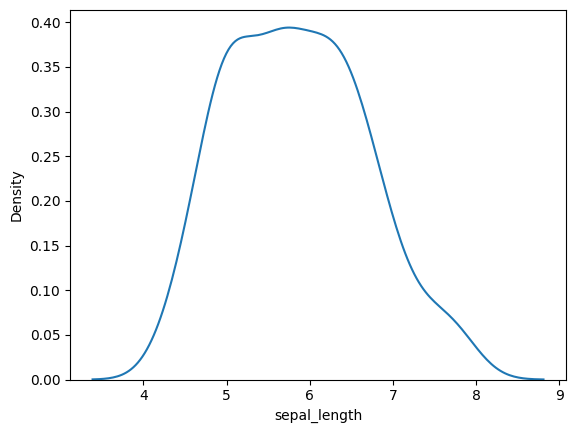

In [36]:
sns.kdeplot(iris["sepal_length"])

In [37]:
temp=sorted(iris['sepal_length'].tolist())

In [38]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [39]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [40]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

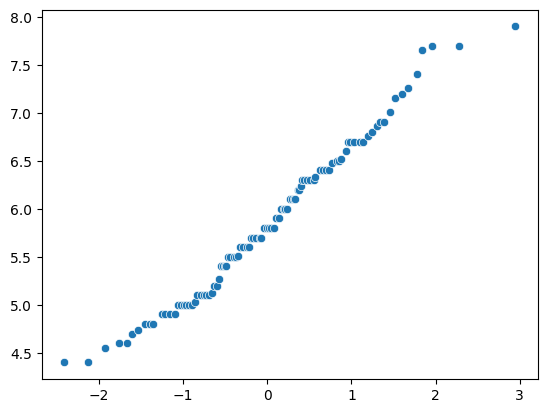

In [41]:
sns.scatterplot(x=x_quant,y=y_quant)

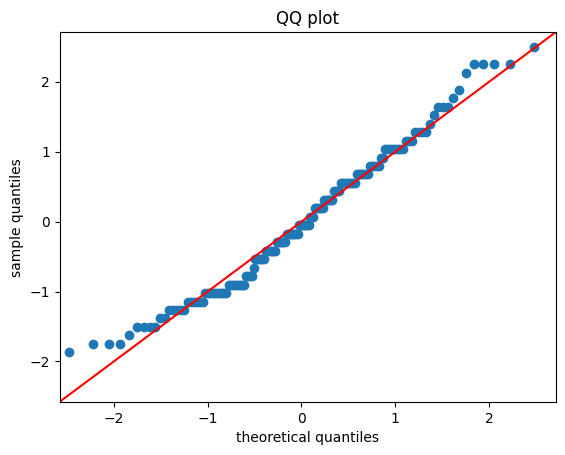

In [42]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [43]:
import scipy.stats as stats

In [44]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([ 92., 107.,  98.,  94., 116., 100.,  93.,  92., 103., 105.]),
 array([2.25768266e-04, 1.00158421e-01, 2.00091073e-01, 3.00023726e-01,
        3.99956378e-01, 4.99889031e-01, 5.99821683e-01, 6.99754336e-01,
        7.99686988e-01, 8.99619641e-01, 9.99552293e-01]),
 <BarContainer object of 10 artists>)

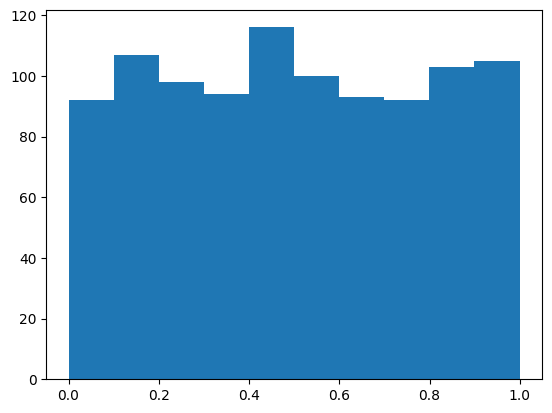

In [45]:
plt.hist(x)

PARETO DISTRIBUTION

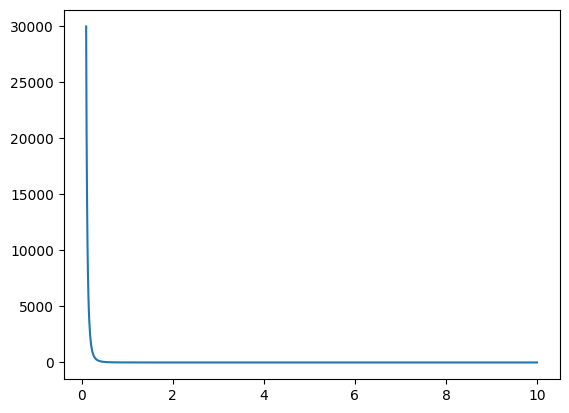

In [46]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

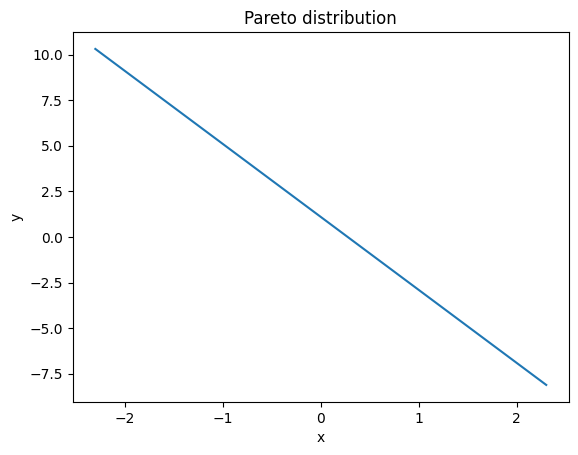

In [47]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [48]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([974.,  19.,   4.,   0.,   1.,   1.,   0.,   0.,   0.,   1.]),
 array([ 1.00037569,  6.07605154, 11.15172739, 16.22740324, 21.30307908,
        26.37875493, 31.45443078, 36.53010663, 41.60578247, 46.68145832,
        51.75713417]),
 <BarContainer object of 10 artists>)

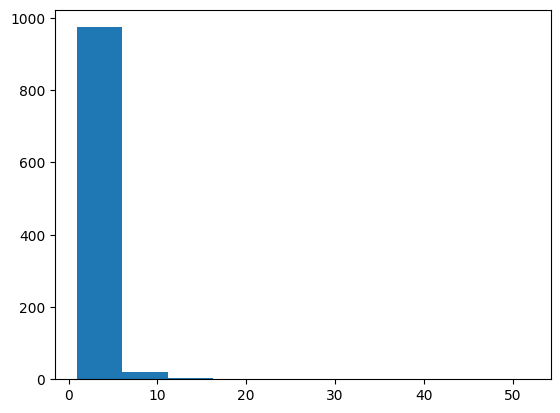

In [49]:
plt.hist(x)

In [50]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

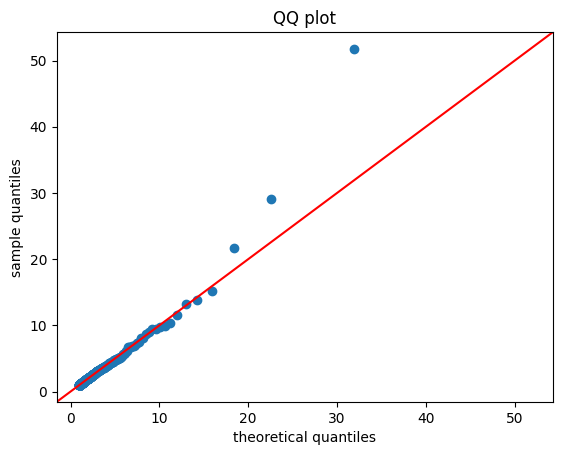

In [51]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [52]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url,usecols=['Battery Age','Cycle Count','Daily Usage Hours'])
battery_csv=df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [53]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [54]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [55]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Gaming User,0
Design Capacity,0
Cycle Count,0
CPU Usage,0
GPU Usage,0
Power Consumption,0
Average Temperature,0
Full Charge Capacity,0


In [56]:
x=df.iloc[:,1:5]
y=df.iloc[:,0]

In [57]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

/tmp/ipykernel_1722/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

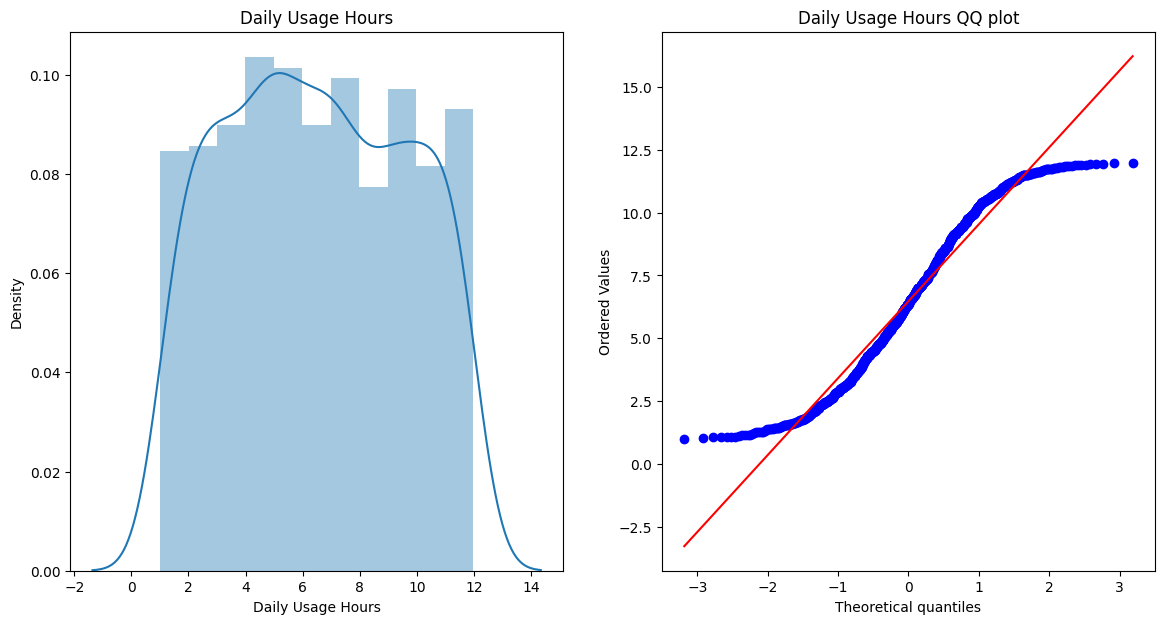

In [58]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

Text(0.5, 1.0, 'Cycle Count QQ plot')

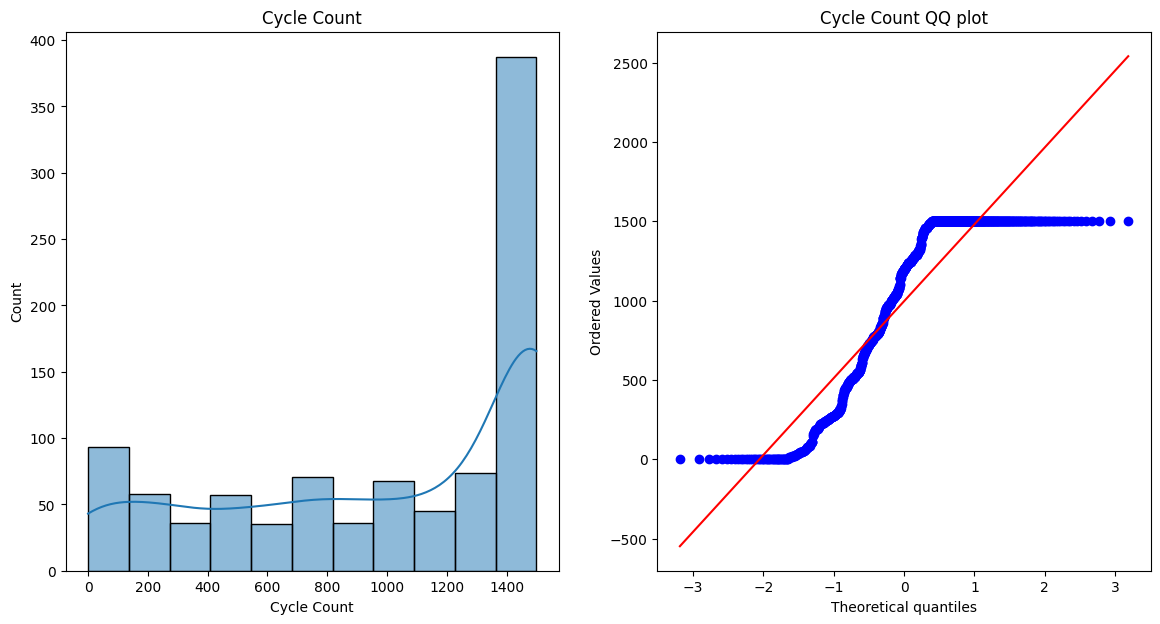

In [59]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.histplot(x_train['Cycle Count'], kde=True)
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")

In [60]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [61]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 4) (1200,)


In [62]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
0           9.797617            0            57884         1267
1           7.101557            0            63824         1500
2          10.085255            0            79414         1500
3           7.946047            0            61142         1153
4           9.628460            0            50956         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Gaming User             2
Design Capacity      1175
Cycle Count           562
dtype: int64


In [63]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [64]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.42916666666666664
Accuracy DT 0.75


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [65]:
trf=FunctionTransformer(np.log1p)

In [66]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

     Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
497           0.905877     0.000000        11.115607     6.645091
979           2.123932     0.693147        11.208585     1.609438
916           2.096124     0.693147        10.722981     7.313887
633           0.888679     0.000000        10.766842     6.796824
585           1.751538     0.000000        10.726785     5.863631
..                 ...          ...              ...          ...
588           1.998710     0.000000        11.006457     3.178054
538           1.165802     0.000000        10.760198     7.313887
386           2.299011     0.000000        11.138407     6.308098
715           2.497255     0.000000        11.015937     7.313887
15            2.157323     0.693147        11.167077     7.313887

[960 rows x 4 columns]
      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
398            1.517325     0.693147        10.807604     5.231109
60             2.520820     0.000000        11.289

In [67]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.4875
Accuracy DT 0.7416666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PDF of binomial ditribution.

[ 3  5  6  4  6  6  5  3  5  5  4  6  4  3  4  3  6  5  5  5  8  5  5  7
  4  3  4  6  3  5  7  6  7  3  3  6  5  6  7  5  3  3  5  4  4  5  6  6
  7  5  4  5  6  5  8  4  4  3  6  3  4  3  5  6  4  5  5  5  6  6  6  3
  7  5  6  5  3  4  6  3  3  5  7  6  5  7  5  3  5  3  6  6  8  4  6  7
  6  9  2  9  6  7  4  4  8  5  6  3  6  7  6  4  3  4  5  5  4  5  4  4
  6  5  4  4  6  4  4  4  4  5  6  6  4  6  8  6  7  5  6  7  3  9  7  2
  5  3  4  4  3  2  7  5  5  3  5  4  5  4  6  6  6  4  4  4  6  3  5  6
  6  7  5  6  4  5  6  4  6  3  7  7  6  2  7  7  4  4  6  3  2  4  2  5
  5  4  7  5  5  5  4  4  2  4  4  4  7  5  4  6  5  5  5  7  6  4  4  3
  6  6  5  3  7  3  4  6  4  6  8  5  3  4  5  6  6  6  5  4  4  6  7  7
  3  6  6  5  6  6  5  3  4  6  4  6  5  6  5  6  2  8  3  6  3  6  3  3
  4  4  3  5  6  5  5  4  3  5  5  6  7  3  3  2  5  6  6  5  4  4  6  4
  4  6  5  7  5  2  6  6  6  4  5  5  4  7  4  3  3  5  5  6  3  5  3  7
  8  4  5  3  3  6  6  7  6  6  4  6  6  7  6  5  3

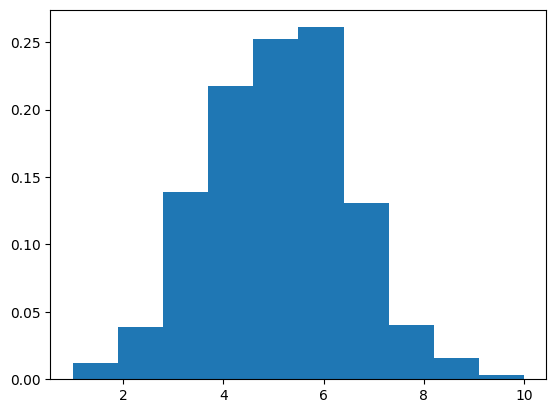

In [68]:
n=10    #number of trials
probability=0.5
binomial_d=np.random.binomial(n=n,p=probability,size=1000)
print(binomial_d)
plt.hist(binomial_d,density=True)
plt.show()
# when probability of success is less left skewed graph and vice versa

Central limit theorem

In [69]:
num_sample=100000
sample_size=300
dist_range=(0,1)

samples=np.random.uniform(dist_range[0],dist_range[1],(num_sample,sample_size))
samples.shape

(100000, 300)

In [70]:
sample_mean=np.mean(samples,axis=1)
sample_mean

array([0.54731262, 0.51440787, 0.47837033, ..., 0.49645375, 0.50267611,
       0.5200921 ])

In [71]:
sample_mean.shape

(100000,)

Text(0.5, 1.0, 'histogram of sample means')

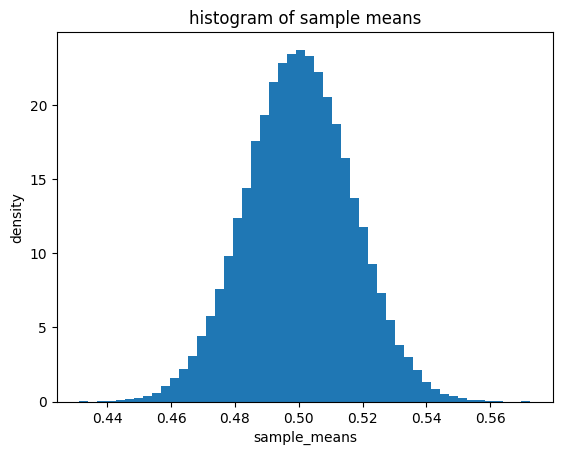

In [72]:
plt.hist(sample_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of sample means")

# greater the number of samples ,gratere is the chances of normal distribution

Different different distributions.

In [73]:
sample_nums=10000
sample_size=50

#poisson distribution parameters
poisson_lambda=5

#gamma distribution parameters
gamma_shape=2
gamma_scale=1

#binomial distribution parameters
binomial_n=10
binomial_p=0.5

# generation
poisson_d=np.random.poisson(lam=poisson_lambda,size=(sample_nums,sample_size))
gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(sample_nums,sample_size))
binomial_d=np.random.binomial(n=binomial_n,p=binomial_p,size=(sample_nums,sample_size))

#calculate means
poisson_mean=np.mean(poisson_d,axis=1)
gamma_mean=np.mean(gamma_d,axis=1)
binomial_mean=np.mean(binomial_d,axis=1)


Text(0.5, 1.0, 'histogram of biomial means')

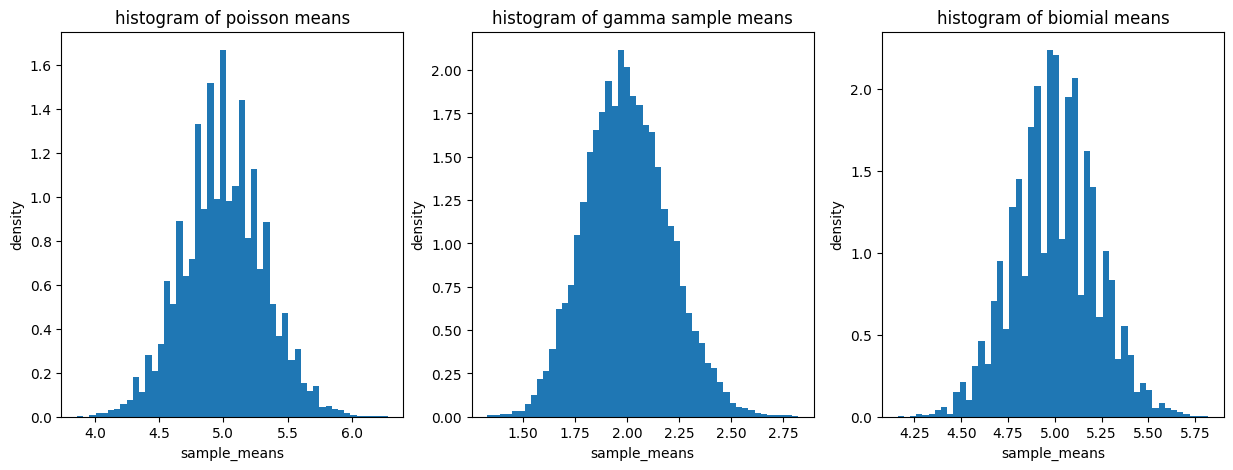

In [74]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1,)
plt.hist(poisson_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of poisson means")

plt.subplot(1,3,2)
plt.hist(gamma_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of gamma sample means")

plt.subplot(1,3,3)
plt.hist(binomial_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of biomial means")

In [75]:
gamma_samples=1000
gamma_size=30

gamma_shape=2
gamma_scale=1

theorotical_mean=gamma_shape*gamma_scale
theorotical_var=(gamma_shape*gamma_scale**2)

gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(gamma_samples,gamma_size))

gamma_means=np.mean(gamma_d,axis=1)
emperical_mean=np.mean(gamma_means)
emperical_var=np.var(gamma_means)

print("Theorotical mean:",theorotical_mean)
print("Theorotical variance:",theorotical_var)
print("Emperical mean:",emperical_mean)
print("Emperical variance:",emperical_var)


Theorotical mean: 2
Theorotical variance: 2
Emperical mean: 2.0052092126299943
Emperical variance: 0.0628362813826275


CASE STUDY

In [76]:
battery_csv.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [77]:
battery_csv.shape

(1200, 11)

In [78]:
d=battery_csv.sample(1200)
d

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
1017,5,8.644671,0,69154,1250,59.852467,42.310212,79.446895,33.023817,57246.883837,82.470372
372,8,5.787885,0,78787,1500,41.785229,28.631030,57.164298,28.358275,61978.106896,79.356571
746,8,10.175805,1,54475,1500,92.543513,81.347427,114.968106,35.779095,37234.771080,65.923500
431,3,4.386011,0,79568,801,45.065425,34.845111,65.834532,32.778193,70774.434188,88.025264
863,7,2.987233,1,68017,1500,55.619990,54.010108,75.572787,30.380923,52407.905040,78.928966
...,...,...,...,...,...,...,...,...,...,...,...
737,1,3.638019,0,54386,261,38.103732,23.520930,63.718190,27.236595,52239.722828,95.045816
1090,8,3.320669,1,61571,1500,63.373716,59.112581,83.833129,29.352859,46098.461112,75.077466
132,2,7.531587,0,51668,548,49.261937,29.843024,61.209955,30.249990,46297.412815,88.844248
576,7,7.571722,0,77542,1500,49.810937,31.651302,57.152230,29.610106,61751.830153,78.512857


In [79]:
d['Daily Usage Hours'].mean()

np.float64(6.43507813125098)

<Axes: ylabel='Density'>

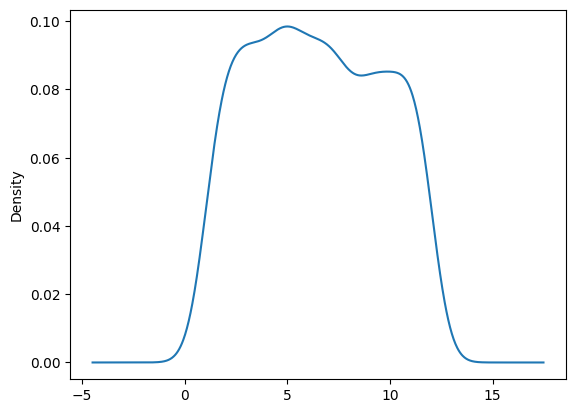

In [80]:
d['Daily Usage Hours'].plot(kind='density')

In [81]:
# taking out 50 samples
df['Daily Usage Hours'].sample(50)

,Daily Usage Hours
4,9.628460
222,2.519378
101,9.790738
37,7.226203
476,5.147593
129,6.321828
827,1.378744
1132,9.428700
557,4.384470
619,3.376346


In [82]:
# converting into pyhton list
df['Daily Usage Hours'].sample(50).values.tolist()

[5.779840596349449,
 4.434087102260424,
 6.481663311236609,
 2.828522982568246,
 6.215737404669876,
 8.608212170531957,
 4.335417622286756,
 10.333189518468911,
 3.425364033562242,
 9.080691307815886,
 10.891738101181229,
 11.523924772782848,
 6.379532404942116,
 7.938474621898827,
 7.561137829548981,
 9.958223127359895,
 4.1104200276610845,
 3.033222377417274,
 8.627152923707378,
 8.131272800286816,
 11.60053707555754,
 2.8280349957072413,
 8.442789569077572,
 7.602765511095414,
 5.891840545441694,
 4.623171962322833,
 3.6211863760840073,
 2.3239993383098465,
 1.551928853519714,
 4.274153053251085,
 6.698852478443793,
 2.6187957620443987,
 7.293352600944269,
 1.5422394204085808,
 4.606723934200844,
 11.557701224453352,
 4.02132456766696,
 7.882158683700041,
 1.823854262021821,
 5.711869806257309,
 8.14511607432658,
 3.5116437760547194,
 5.203534223158262,
 1.2482096287588196,
 1.849062832491148,
 7.983973250684791,
 4.587872795410789,
 4.481028439618578,
 4.278728212870046,
 2.4661268

In [83]:
samples=[]
for i in range(100):
  samples.append(df['Daily Usage Hours'].sample(50).values.tolist())

In [84]:
samples

[[4.01386909416969,
  10.877507378035212,
  1.0680220490498633,
  6.549532164603193,
  9.5193416343177,
  5.555551750372328,
  6.036903246397785,
  3.010947273931485,
  10.15872950658744,
  10.862321243159112,
  4.773293838490268,
  2.9999941812107265,
  4.926806724155303,
  9.182957060323671,
  2.1728598083025767,
  11.476254276385973,
  7.948946601592424,
  5.574004248202521,
  6.068069602658412,
  2.86875780540963,
  1.7993214633927237,
  1.6020597761748447,
  5.2465602921701935,
  6.560728708958393,
  7.4027714423664595,
  7.30919608029381,
  11.906860534101252,
  9.887530609199208,
  5.177111453038136,
  6.992811938037082,
  1.823854262021821,
  4.40416503997461,
  4.71063669730342,
  2.7461043971174046,
  4.837150982044932,
  7.711187142398581,
  8.494103215856772,
  2.199149772050216,
  9.544782809294938,
  7.566397457544898,
  3.494498878516102,
  7.331527715040902,
  4.4421150283170485,
  9.76084617675825,
  11.484321258335516,
  8.627152923707378,
  1.9346291887841307,
  7.66

In [85]:
samples=np.array(samples)
samples

array([[ 4.01386909, 10.87750738,  1.06802205, ...,  7.66486497,
         8.59051577,  3.82311928],
       [ 8.29460874,  4.48636884, 10.76215834, ...,  3.82768961,
         2.47155959,  6.18789002],
       [ 4.54274289, 10.43643562, 10.21219772, ...,  3.30007101,
         6.06361956,  2.46310779],
       ...,
       [ 8.45495565, 10.50802893,  6.2157374 , ...,  1.40107156,
         2.29769732,  4.29887352],
       [ 4.16262319,  9.91177199,  4.345041  , ...,  2.57095735,
        11.81241568,  4.82857151],
       [ 9.45621844,  3.49449888,  3.16135664, ...,  2.99999418,
         1.60071334,  7.32566631]])

In [86]:
# calculate mean for each row
sampling_means=samples.mean(axis=1)

In [87]:
sampling_means.mean()

np.float64(6.482698371627687)

In [88]:
sampling_means.std()/np.sqrt(50)

np.float64(0.05376024161943837)

<Axes: ylabel='Density'>

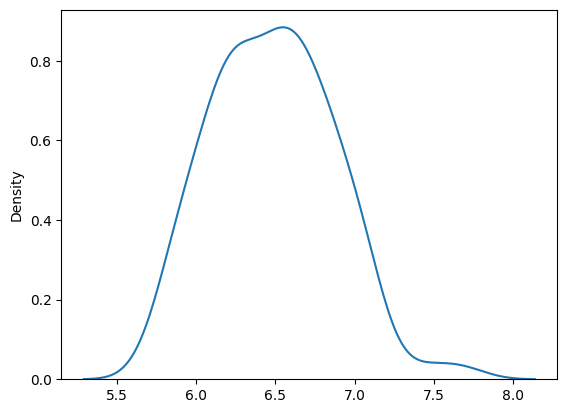

In [89]:
sns.kdeplot(data=sampling_means)

In [90]:
lower_limit=sampling_means.mean()-2*sampling_means.std()/np.sqrt(50)
upper_limit=sampling_means.mean()+2*sampling_means.std()/np.sqrt(50)

print("the range is:",lower_limit,"-",upper_limit)

the range is: 6.37517788838881 - 6.5902188548665634


t-test

In [91]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [92]:
train=df.drop(columns=['Battery Health'])
test=df['Battery Health']

In [93]:
final=pd.concat([train,test]).sample(1000)

In [94]:
corr = df.corr(numeric_only=True)['Battery Health'].drop(
    'Battery Health'
)
print(corr)

Battery Age            -0.900723
Daily Usage Hours      -0.084347
Gaming User             0.018509
Design Capacity         0.289450
Cycle Count            -0.921454
CPU Usage              -0.052363
GPU Usage              -0.033122
Power Consumption      -0.048988
Average Temperature    -0.041134
Full Charge Capacity    0.704030
Name: Battery Health, dtype: float64


In [95]:
meanf=np.mean(df['Full Charge Capacity'])
print(meanf)

51798.12594357623


In [96]:
#H_0:u=51798.13
#H_a:u!=51798.13

In [97]:
vals=final['Full Charge Capacity'].dropna()

In [98]:
sample_vals=vals.sample(200).values
sample_vals

array([47308.6605625 , 68759.78459188, 71164.26586773, 47733.33556686,
       39848.14794672, 39524.04951626, 55375.46768062, 48525.59471078,
       29474.16992036, 59330.25072105, 67529.0760303 , 43142.04922633,
       60422.0828341 , 45421.45717417, 37362.03997966, 59915.        ,
       42854.17052703, 44112.04142459, 67294.84199219, 67111.07605578,
       28356.62134721, 43583.58263049, 65442.9897887 , 64632.17179689,
       51967.95890742, 61291.40447723, 48179.8411504 , 50221.21291403,
       72191.87526442, 58508.62663804, 32887.03298191, 41787.24762661,
       49311.52606093, 57561.        , 75447.19863344, 43883.20516323,
       62066.44315382, 57848.51525397, 64853.08603473, 59115.33698847,
       66478.33754686, 43225.62874759, 59169.73441689, 70117.        ,
       40044.76284737, 53305.92779465, 60730.1672556 , 54409.03781822,
       57067.67601982, 66846.76789487, 38673.5229038 , 63796.48736233,
       46750.19894633, 42766.13225042, 43513.36320259, 51936.23988178,
      

In [99]:
mean_s=np.mean(sample_vals)
print(mean_s)
std_s=np.std(sample_vals)
print(std_s)

53362.5284518085
11438.450835337293


In [100]:
#check normality using shapiro wilk test
from scipy.stats import shapiro

shapiro_s=shapiro(sample_vals)
print(shapiro_s)

ShapiroResult(statistic=np.float64(0.9839482601307734), pvalue=np.float64(0.022256501760360942))


In [101]:
import scipy.stats as stats

t_statistics,p_value=stats.ttest_1samp(sample_vals,50000)
print(t_statistics,p_value/2)


4.146916551604735 2.493592643568759e-05
